# 07 Imbalance experiment

XGBoost with the same settings as `02_xgboost`. Four versions: (a) no handling, (b) `scale_pos_weight`, (c) SMOTE, (d) random undersampling. Official run: CPU (see `docs/decisions.md`, 2026-11-12). Uses the GPU automatically if one is present.

## Setup

In [1]:
# Setup: in Colab, clone the repo and install packages. Locally, use the checkout.
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import userdata
    token = userdata.get('GH_TOKEN')
    if not os.path.exists('/content/credit-card-fraud-detection'):
        !git clone -q https://{token}@github.com/VanshSharmaPES/credit-card-fraud-detection.git /content/credit-card-fraud-detection
    %cd /content/credit-card-fraud-detection
    !pip install -q -r requirements/base.txt -r requirements/xgboost.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
!{sys.executable} src/data.py
sys.path.append('src')

Raw rows: 284807, raw frauds: 492
Duplicates dropped: 1081
Rows after cleaning: 283726, frauds: 473
train rows:  170235  frauds:  284  fraud share: 0.1668%
val   rows:   56745  frauds:   94  fraud share: 0.1657%
test  rows:   56746  frauds:   95  fraud share: 0.1674%
Class weight (train normal / train fraud): 169951 / 284 = 598.4190


In [2]:
import json
import random
import shutil
import subprocess
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from data import load_splits
from evaluate import evaluate_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Use the GPU when there is one. The official run is on CPU (docs/decisions.md).
def gpu_name():
    if shutil.which('nvidia-smi') is None:
        return None
    out = subprocess.run(['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'],
                         capture_output=True, text=True)
    return out.stdout.strip().splitlines()[0] if out.returncode == 0 and out.stdout.strip() else None

GPU = gpu_name()
DEVICE = 'cuda' if GPU else 'cpu'
def cpu_name():
    import platform
    try:
        for line in open('/proc/cpuinfo'):
            if line.startswith('model name'):
                return line.split(':', 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()

HARDWARE = f'Colab {GPU}' if (GPU and IN_COLAB) else (GPU or f'CPU: {cpu_name()} ({os.cpu_count()} threads)')
print('xgboost', xgb.__version__, '| device:', DEVICE, '| hardware:', HARDWARE)
if GPU is None:
    print('No GPU found: running on CPU.')

FIG_DIR, MODEL_DIR = Path('figures'), Path('models')
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'legend.frameon': False,
})

xgboost 3.4.1 | device: cpu | hardware: CPU: AMD Ryzen 5 5600H with Radeon Graphics (12 threads)
No GPU found: running on CPU.


## Load the data

In [3]:
(X_train, y_train, X_val, y_val, X_test, y_test,
 rowid_val, rowid_test, amount_val, amount_test) = load_splits()

CLASS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print('Train / val / test rows:', len(X_train), len(X_val), len(X_test))
print('Features:', X_train.shape[1])
print(f'Class weight (train normal / train fraud): {CLASS_WEIGHT:.4f}')
assert X_train.shape[1] == 30
assert round(CLASS_WEIGHT, 4) == 598.4190, "Class weight differs from the data.py summary"

Train / val / test rows: 170235 56745 56746
Features: 30
Class weight (train normal / train fraud): 598.4190


## Training function

In [4]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler


def train_xgb(X, y, scale_pos_weight):
    """Same settings as 02_xgboost. Early stopping always uses the real validation set."""
    model = xgb.XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=6, scale_pos_weight=scale_pos_weight,
        eval_metric='aucpr', early_stopping_rounds=50, device=DEVICE, random_state=SEED,
    )
    start = time.perf_counter()
    model.fit(X, y, eval_set=[(X_val, y_val)], verbose=False)
    return model, time.perf_counter() - start

## The four training sets

In [5]:
# Resampling is applied to the training split only. Validation and test are never touched.
X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
X_under, y_under = RandomUnderSampler(random_state=SEED).fit_resample(X_train, y_train)

VERSIONS = {
    # name: (description, X, y, scale_pos_weight)
    'imb_a_none':        ('(a) No handling',          X_train, y_train, 1),
    'imb_b_weight':      ('(b) scale_pos_weight',     X_train, y_train, CLASS_WEIGHT),
    'imb_c_smote':       ('(c) SMOTE',                X_smote, y_smote, 1),
    'imb_d_undersample': ('(d) Random undersampling', X_under, y_under, 1),
}
for name, (desc, X, y, w) in VERSIONS.items():
    print(f'{desc:<26} rows: {len(X):>7,}  frauds: {int(y.sum()):>7,}  scale_pos_weight: {w:.4f}')

(a) No handling            rows: 170,235  frauds:     284  scale_pos_weight: 1.0000
(b) scale_pos_weight       rows: 170,235  frauds:     284  scale_pos_weight: 598.4190
(c) SMOTE                  rows: 339,902  frauds: 169,951  scale_pos_weight: 1.0000
(d) Random undersampling   rows:     568  frauds:     284  scale_pos_weight: 1.0000


## Train and evaluate

In [6]:
# imb_* names and folder='imbalance' keep these apart from results/xgboost.json and preds/xgboost_*.csv
results = {}
for name, (desc, X, y, w) in VERSIONS.items():
    model, train_seconds = train_xgb(X, y, w)
    p_val = model.predict_proba(X_val)[:, 1]
    start = time.perf_counter()
    p_test = model.predict_proba(X_test)[:, 1]
    predict_seconds = time.perf_counter() - start
    evaluate_model(
        name,
        y_val=y_val, p_val=p_val, y_test=y_test, p_test=p_test,
        row_id_val=rowid_val, row_id_test=rowid_test,
        train_seconds=train_seconds, predict_seconds=predict_seconds,
        hardware=HARDWARE,
        notes=f'{desc}; train rows={len(X)}; scale_pos_weight={w:.4f}; best_iteration={model.best_iteration}',
        folder='imbalance',  # writes results/imbalance/ and preds/imbalance/
    )
    results[name] = json.loads(Path(f'results/imbalance/{name}.json').read_text())
    print(f'{desc:<26} best_iteration {model.best_iteration:>4} | {train_seconds:6.1f} s')

table = pd.DataFrame(results).T
table.insert(0, 'version', [VERSIONS[n][0] for n in table.index])
table[['version', 'threshold', 'precision', 'recall', 'f1', 'pr_auc', 'roc_auc', 'tp', 'fp', 'fn', 'train_seconds']]

(a) No handling            best_iteration  203 |    5.5 s


(b) scale_pos_weight       best_iteration  265 |    4.7 s


(c) SMOTE                  best_iteration  404 |   10.8 s


(d) Random undersampling   best_iteration  108 |    1.0 s


,version,threshold,precision,recall,f1,pr_auc,roc_auc,tp,fp,fn,train_seconds
imb_a_none,(a) No handling,0.253914,0.939024,0.810526,0.870056,0.845081,0.976022,77,5,18,5.460814
imb_b_weight,(b) scale_pos_weight,0.939403,0.974026,0.789474,0.872093,0.838184,0.971891,75,2,20,4.713662
imb_c_smote,(c) SMOTE,0.916416,0.961039,0.778947,0.860465,0.85723,0.980438,74,3,21,10.784849
imb_d_undersample,(d) Random undersampling,0.985157,0.791667,0.8,0.795812,0.792211,0.979722,76,20,19,0.975041


## Comparison chart

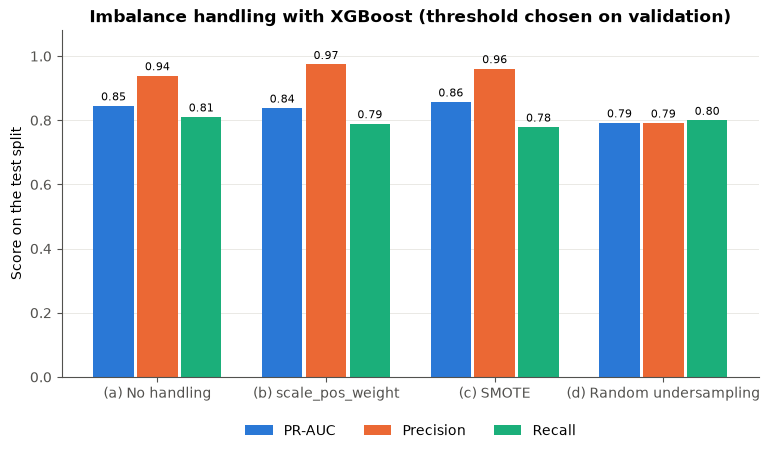

In [7]:
metrics = ['pr_auc', 'precision', 'recall']
labels = {'pr_auc': 'PR-AUC', 'precision': 'Precision', 'recall': 'Recall'}
colours = {'pr_auc': '#2a78d6', 'precision': '#eb6834', 'recall': '#1baf7a'}

x = np.arange(len(table))
width = 0.26
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, m in enumerate(metrics):
    vals = table[m].astype(float).values
    bars = ax.bar(x + (i - 1) * width, vals, width - 0.02, color=colours[m], label=labels[m])
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=8)
ax.set_xticks(x, table['version'])
ax.set_ylim(0, 1.08)
ax.set_ylabel('Score on the test split')
ax.set_title('Imbalance handling with XGBoost (threshold chosen on validation)')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
ax.grid(axis='x', visible=False)
fig.savefig(FIG_DIR / 'imbalance_comparison.png', dpi=150, bbox_inches='tight')
plt.show()